# E12 · Lens design with a measurable objective

Bend a singlet without changing its paraxial focal power. Choose a common image plane, minimize a stated geometric error, and check what the design sacrifices away from the centre.

<!-- course-motivation:start -->
## Why learn this?

**Which lens is better for the image you need?**

Two lenses can have the same focal length yet form different finite-aperture spots. Improving the centre may worsen the edge. A useful design process must state the required field, pupil and image plane before it changes the surface shapes.

**What you gain:** Turn an imaging requirement into a reproducible objective, optimize within physical constraints and explain the tradeoffs that remain after the score improves.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Ray states and lens reference planes:** Trace a prescribed lens and interpret an image-plane ray intersection. Used here: Every trial design is evaluated by the same forward ray model. [Review: MIT OCW · Thick lenses, lecture 5](https://ocw.mit.edu/courses/2-71-optics-spring-2009/pages/lecture-slides/). Read the thick-lens and principal-plane diagrams. E11 develops the actual surface-intersection and refraction algorithm.
- **Weighted means and squared error:** Distinguish the centroid of a spot from its spread and combine weighted errors. Used here: The objective compares geometric spot variances across specified fields. [Review: MIT OCW · Aberrations and optical design, lectures 8–9](https://ocw.mit.edu/courses/2-71-optics-spring-2009/pages/lecture-slides/). Use the spot diagrams to separate image position from image spread. The lesson defines its own RMS metric and field weights explicitly.

**Python preparation:** Evaluate a function on a parameter grid, record the best valid trial and recheck it with denser sampling.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.

**Developed here:** Define and optimize a constrained lens-design objective. Calculus-based optimization and an adjoint solver are not required for the core experiment.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Separate a lens prescription, a performance metric and the constraints that keep the task unchanged.
- Compare on-axis and multi-field optimization using one common image plane and the same entrance aperture.
- Audit an improved design with denser pupil sampling and explain the image-quality questions its merit function omits.

**Model:** Monochromatic sequential geometric design of a single spherical lens in air: n = 1.5, centre thickness 4 mm and paraxial EFL 50 mm. Only bending and a common image position are optimized at fixed entrance aperture. RMS is measured about each field centroid. Diffraction, chromatic aberration, distortion targets, polarization, Fresnel power weights and manufacturing tolerances are not optimized.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e12_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.11.7 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


## 1 · Specify a lens family before choosing an optimizer

We design a two-surface spherical singlet in air. The entrance stop is fixed at
z = −5 mm, and the mechanical clear radius is 12 mm. Index n = 1.5, centre thickness
d = 4 mm, and paraxial effective focal length f = 50 mm remain fixed. The shape variable
q=(c₁+c₂)/(c₁−c₂), with c=1/R, changes bending while preserving thick-lens power:
Φ=(n−1)[c₁−c₂+(n−1)d c₁c₂/n]. The second variable is one detector z for **all fields**.

**Predict:** can two lenses with the same paraxial focal length have different spot sizes?
The following self-contained engine is the same source used by E11 and the film.
Run it once; study intersection and vector Snell details in E11. No external files are loaded.

In [2]:
#@title Self-contained geometric-ray engine from E11
from math import acos, cos, copysign, hypot, inf, isfinite, pi, sin, sqrt


def dot(a, b):
    return sum(x * y for x, y in zip(a, b))

def unit(v):
    length = sqrt(dot(v, v))
    if not isfinite(length) or length <= 0:
        raise ValueError("A ray direction must have a finite positive length.")
    return [x / length for x in v]

def curvature(radius):
    return 0.0 if radius is None or not isfinite(radius) else 1.0 / radius

def surface_sag(radius, rho):
    c = curvature(radius)
    radicand = 1 - (c * rho) ** 2
    if radicand < -1e-12:
        return float("nan")
    return c * rho * rho / (1 + sqrt(max(0.0, radicand)))

def make_lens(r1=50.0, r2=-50.0, thickness=4.0, index=1.5, clear_radius=12.0):
    if thickness <= 0 or index <= 0 or clear_radius <= 0:
        raise ValueError("Thickness, refractive index, and clear radius must be positive.")
    radii = [None if r is None or not isfinite(r) else float(r) for r in (r1, r2)]
    if any(r == 0 for r in radii):
        raise ValueError("Zero radius is not a plane; use None or infinity.")
    edge = thickness + surface_sag(radii[1], clear_radius) - surface_sag(radii[0], clear_radius)
    return dict(r1=radii[0], r2=radii[1], thickness=float(thickness), index=float(index),
                clear_radius=float(clear_radius), edge_thickness=edge)

def paraxial(lens):
    """Independent first-order thick-lens prediction, object at infinity in air."""
    n, d = lens["index"], lens["thickness"]
    c1, c2 = curvature(lens["r1"]), curvature(lens["r2"])
    power = (n - 1) * (c1 - c2 + (n - 1) * d * c1 * c2 / n)
    focal = 1 / power if abs(power) > 1e-15 else inf
    bfl = focal * (1 - (n - 1) * d * c1 / n)
    return dict(power=power, focal=focal, bfl=bfl, image_z=d + bfl)

def prescription(shape=0.0, focal=50.0, index=1.5, thickness=4.0, clear_radius=12.0):
    """Vary q=(c1+c2)/(c1-c2), keeping the paraxial thick-lens power fixed."""
    if focal <= 0 or index <= 1 or abs(shape) > 1.2 + 1e-12:
        raise ValueError("Use positive focal length, n>1, and -1.2 <= shape <= 1.2.")
    b = 1 / (focal * (index - 1))
    a = (index - 1) * thickness * (shape * shape - 1) / (4 * index)
    discriminant = 1 + 4 * a * b
    if discriminant <= 0:
        raise ValueError("No real prescription on the selected weak-curvature branch.")
    delta = 2 * b / (1 + sqrt(discriminant))
    c1, c2 = delta * (shape + 1) / 2, delta * (shape - 1) / 2
    lens = make_lens(None if abs(c1) < 1e-15 else 1 / c1,
                     None if abs(c2) < 1e-15 else 1 / c2, thickness, index, clear_radius)
    lens.update(shape=float(shape), target_focal=float(focal))
    return lens

def intersect_surface(origin, direction, vertex, radius, clear_radius=12.0):
    """Nearest forward intersection with the physical cap, never the far hemisphere."""
    direction = unit(direction)
    if curvature(radius) == 0:
        roots = [] if abs(direction[2]) < 1e-14 else [(vertex - origin[2]) / direction[2]]
    else:
        relative = [origin[0], origin[1], origin[2] - vertex - radius]
        b, c = 2 * dot(relative, direction), dot(relative, relative) - radius * radius
        disc = b * b - 4 * c
        if disc < -1e-10:
            return dict(status="missed")
        q = -.5 * (b + copysign(sqrt(max(0.0, disc)), b))
        roots = [q, c / q] if abs(q) > 1e-15 else [-b / 2]
    for t in sorted(roots):
        if t <= 1e-9:
            continue
        point = [o + t * v for o, v in zip(origin, direction)]
        rho = hypot(point[0], point[1])
        sag = surface_sag(radius, rho)
        if not isfinite(sag) or abs(point[2] - vertex - sag) > 1e-7 * max(1, abs(vertex), abs(point[2])):
            continue
        if rho > clear_radius + 1e-9:
            return dict(status="blocked", point=point, distance=t)
        normal = [0., 0., 1.] if curvature(radius) == 0 else unit([point[0], point[1], point[2] - vertex - radius])
        if dot(direction, normal) < 0:
            normal = [-x for x in normal]
        return dict(status="ok", point=point, distance=t, normal=normal)
    return dict(status="missed")

def refract(direction, normal, n_before, n_after):
    """Vector Snell law; normal is oriented into the transmitted medium."""
    d, normal = unit(direction), unit(normal)
    if dot(d, normal) < 0:
        normal = [-x for x in normal]
    cosine = max(0., min(1., dot(d, normal)))
    eta = n_before / n_after
    tangential = [d[i] - cosine * normal[i] for i in range(3)]
    radicand = 1 - eta * eta * dot(tangential, tangential)
    if radicand < -1e-12:
        return dict(status="tir", normal=normal, cos_incident=cosine)
    transmitted = sqrt(max(0., radicand))
    return dict(status="ok", direction=unit([eta * tangential[i] + transmitted * normal[i] for i in range(3)]),
                normal=normal, cos_incident=cosine, cos_transmitted=transmitted)

def trace_ray(origin, direction, lens, image_z=None):
    point, direction = list(origin), unit(direction)
    points, surfaces = [point[:]], []
    for number, (vertex, radius, ni, nt) in enumerate([(0., lens["r1"], 1., lens["index"]),
            (lens["thickness"], lens["r2"], lens["index"], 1.)], 1):
        hit = intersect_surface(point, direction, vertex, radius, lens["clear_radius"])
        hit["surface"] = number
        surfaces.append(hit)
        if "point" in hit:
            points.append(hit["point"])
        if hit["status"] != "ok":
            return dict(status=hit["status"], points=points, surfaces=surfaces, failed_surface=number,
                        exit=None, direction=None, image=None)
        bent = refract(direction, hit["normal"], ni, nt)
        hit.update(n_before=ni, n_after=nt, incoming=direction, outgoing=bent.get("direction"))
        if bent["status"] != "ok":
            return dict(status=bent["status"], points=points, surfaces=surfaces, failed_surface=number,
                        exit=None, direction=None, image=None)
        point, direction = hit["point"], bent["direction"]
    image = None
    if image_z is not None:
        t = (image_z - point[2]) / direction[2] if abs(direction[2]) > 1e-14 else -1
        if t < 0:
            return dict(status="image_behind_lens", points=points, surfaces=surfaces,
                        exit=point, direction=direction, image=None)
        image = [p + t * v for p, v in zip(point, direction)]
        points.append(image)
    return dict(status="ok", points=points, surfaces=surfaces, exit=point, direction=direction, image=image)

def pupil_ray(x, y, field_deg, lens, image_z=None, launch_z=-10.0, pupil_z=-5.0):
    theta = field_deg * pi / 180
    direction = [sin(theta), 0., cos(theta)]
    origin = [x + (launch_z - pupil_z) * direction[0] / direction[2], y, launch_z]
    result = trace_ray(origin, direction, lens, image_z)
    result["pupil"] = [x, y]
    return result

def pupil_samples(aperture, rings=6, spokes=16):
    """Equal-area annuli, midpoint radial quadrature, equal weights per ray."""
    if aperture <= 0 or rings < 1 or spokes < 4:
        raise ValueError("Use a positive pupil and at least one ring/four spokes.")
    return [[aperture * sqrt((j + .5) / rings) * cos(2 * pi * (k + .5 * (j % 2)) / spokes),
             aperture * sqrt((j + .5) / rings) * sin(2 * pi * (k + .5 * (j % 2)) / spokes)]
            for j in range(rings) for k in range(spokes)]

def trace_bundle(lens, aperture, field_deg, image_z, rings=6, spokes=16):
    rays = [pupil_ray(x, y, field_deg, lens, image_z) for x, y in pupil_samples(aperture, rings, spokes)]
    accepted = [r for r in rays if r["status"] == "ok"]
    xy = [r["image"][:2] for r in accepted if r["image"] is not None]
    centroid = [sum(p[i] for p in xy) / len(xy) for i in range(2)] if xy else None
    rms = sqrt(sum(sum((p[i] - centroid[i]) ** 2 for i in range(2)) for p in xy) / len(xy)) if xy else None
    return dict(rays=rays, xy=xy, centroid=centroid, rms_mm=rms, requested=len(rays),
                accepted=len(accepted), throughput=len(accepted) / len(rays), field_deg=field_deg, image_z=image_z)

def best_image_plane(lens, aperture, fields=(0., 3., 6.), rings=6, spokes=16, bounds=(30., 90.)):
    """Minimize equal-field-weighted centroid RMS² over ONE common axial plane.

    In air after the second surface, x(z)=a+bz. Subtract the centroid separately
    within each field. Sum all field variances before solving the quadratic.
    This removes image displacement from the spot size, but never refocuses fields.
    """
    quadratic, linear = 0., 0.
    for field in fields:
        bundle = trace_bundle(lens, aperture, field, None, rings, spokes)
        accepted = [r for r in bundle["rays"] if r["status"] == "ok" and r["direction"][2] > 0]
        if not accepted:
            return max(bounds[0], min(bounds[1], paraxial(lens)["image_z"]))
        for axis in range(2):
            slopes = [r["direction"][axis] / r["direction"][2] for r in accepted]
            intercepts = [r["exit"][axis] - r["exit"][2] * b for r, b in zip(accepted, slopes)]
            bm, am = sum(slopes) / len(slopes), sum(intercepts) / len(intercepts)
            quadratic += sum((b - bm) ** 2 for b in slopes) / len(slopes)
            linear += sum((a - am) * (b - bm) for a, b in zip(intercepts, slopes)) / len(slopes)
    return max(bounds[0], min(bounds[1], -linear / quadratic)) if quadratic > 1e-20 else bounds[1]

def design_merit(shape, image_z, aperture=6., fields=(0., 3., 6.), rings=6, spokes=16):
    lens = prescription(shape)
    bundles = [trace_bundle(lens, aperture, field, image_z, rings, spokes) for field in fields]
    loss = sum(1 - b["throughput"] for b in bundles) / len(bundles)
    valid = isfinite(lens["edge_thickness"]) and lens["edge_thickness"] >= .5 and loss == 0
    rms2 = sum((b["rms_mm"] or 0.) ** 2 for b in bundles) / len(bundles)
    # Any clipped/lost/TIR ray invalidates the design. A missing ray never helps.
    edge_penalty = max(0., .5 - lens["edge_thickness"]) if isfinite(lens["edge_thickness"]) else 1e3
    value = rms2 if valid else 1e6 + 1e3 * loss + 1e3 * edge_penalty
    return dict(value_mm2=value, valid=valid, loss_fraction=loss, bundles=bundles, lens=lens,
                shape=float(shape), image_z=float(image_z), rms_mm=sqrt(rms2), aperture=aperture,
                fields=list(fields))

def optimize_design(shape=0., aperture=6., fields=(0., 3., 6.), iterations=24, rings=6, spokes=16):
    """Bounded deterministic pattern search; common image plane solved analytically.

    This small educational search is not a claim of global optimality. Aperture,
    field weights, material, thickness, mechanical diameter and paraxial power stay
    fixed. All merit values retain the same physical mm² normalization.
    """
    lens = prescription(shape)
    start = design_merit(shape, paraxial(lens)["image_z"], aperture, fields, rings, spokes)
    best, step, trials = start, .4, 0
    history = [dict(shape=best["shape"], image_z=best["image_z"], value_mm2=best["value_mm2"])]
    for iteration in range(iterations):
        candidates = [best["shape"]] if iteration == 0 else [max(-1.2, best["shape"] - step), min(1.2, best["shape"] + step)]
        improved = False
        for q in candidates:
            trial_lens = prescription(q)
            z = best_image_plane(trial_lens, aperture, fields, rings, spokes)
            result = design_merit(q, z, aperture, fields, rings, spokes)
            trials += 1
            if result["value_mm2"] < best["value_mm2"] - 1e-15:
                best, improved = result, True
        if not improved and iteration > 0:
            step /= 2
        history.append(dict(shape=best["shape"], image_z=best["image_z"], value_mm2=best["value_mm2"]))
        if step < 1e-5:
            break
    return dict(start=start, best=best, history=history, trials=trials, completed=len(history) - 1)

In [3]:
for q in [-1.2,-.6,0.,.6,1.2]:
    lens=prescription(q)
    assert abs(paraxial(lens)["focal"]-50.)<1e-11
    assert lens["edge_thickness"]>=.5
    print(f"q={q:+.2f}, R1={lens['r1']:.3f}, R2={lens['r2']:.3f}, EFL={paraxial(lens)['focal']:.6f}, edge={lens['edge_thickness']:.3f} mm")

q=-1.20, R1=-251.458, R2=-22.860, EFL=50.000000, edge=0.884 mm
q=-0.60, R1=123.924, R2=-30.981, EFL=50.000000, edge=0.999 mm
q=+0.00, R1=49.324, R2=-49.324, EFL=50.000000, edge=1.036 mm
q=+0.60, R1=30.981, R2=-123.924, EFL=50.000000, edge=0.999 mm
q=+1.20, R1=22.860, R2=251.458, EFL=50.000000, edge=0.884 mm


## 2 · Define the merit and the detector before optimizing

Rays uniformly sample area in a fixed 6 mm-radius entrance stop. Within each field,
RMS² is the mean squared distance from the **spot centroid**. Averaging these squared
radii with equal weights across 0°, 3°, and 6° defines the merit in mm². Recentering
a spot removes image height from its size; it does **not** move the detector or correct distortion.

After the rear surface, every ray coordinate is affine in z, x(z)=a+bz. Sum the
within-field variances over all fields **before** minimizing that one quadratic.
This gives one common image plane for a candidate q, never separate best focus per field.
Any lost, blocked, or TIR ray invalidates a candidate and gives a large penalty;
edge thickness must remain at least 0.5 mm. The aperture cannot shrink during the search.
**Predict:** will the best detector position for 0° also minimize the 6° spot?

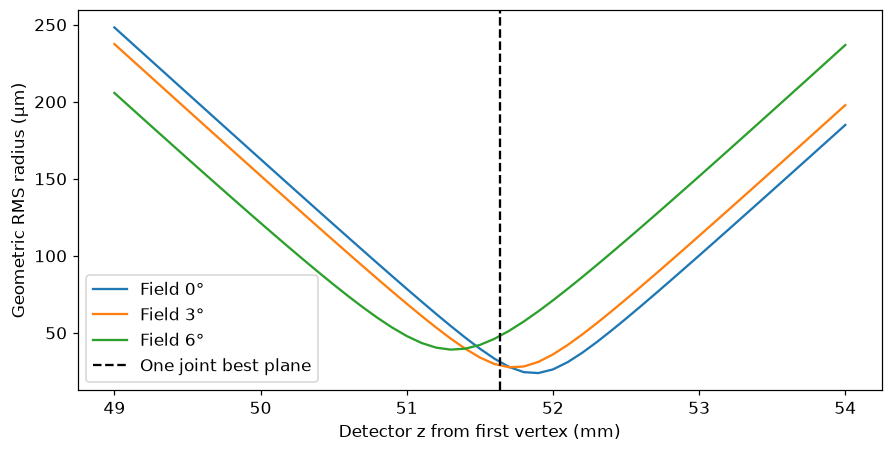

Initial paraxial z: 52.64839839775475 mm; common least-squares z: 51.637690171745845 mm


In [4]:
aperture=6.;fields=[0.,3.,6.];q0=0.
lens0=prescription(q0);z0=paraxial(lens0)["image_z"]
initial=design_merit(q0,z0,aperture,fields)
common=best_image_plane(lens0,aperture,fields)
focus_z=np.linspace(49.,54.,51)
fig,ax=plt.subplots(figsize=(8,4))
for field in fields:
    values=[1000*trace_bundle(lens0,aperture,field,z)["rms_mm"] for z in focus_z]
    ax.plot(focus_z,values,label=f"Field {field:g}°")
ax.axvline(common,color="black",ls="--",label="One joint best plane")
ax.set(xlabel="Detector z from first vertex (mm)",ylabel="Geometric RMS radius (μm)")
ax.legend();show(fig,"01-common-image-plane")
print("Initial paraxial z:",z0,"mm; common least-squares z:",common,"mm")
assert all(b["image_z"]==z0 for b in initial["bundles"])

## 3 · Optimize bending and the common plane

A small bounded pattern search changes q. For each candidate q, the preceding
quadratic solves its one common detector position. This is a two-variable design
with one variable eliminated analytically. It is deterministic and cheap, but
does not claim a global optimum. Search bounds are −1.2 ≤ q ≤ 1.2.
Compare an on-axis objective with the field-weighted objective. A lower number
for a different objective is not automatically a better lens: judge both on the same audit.

On-axis objective : q = 0.6865234375 , common z = 51.22776078515433 , merit = 0.00023856753844424237 mm²
Three-field objective : q = 0.467236328125 , common z = 51.21456626089123 , merit = 0.0010027688477961614 mm²


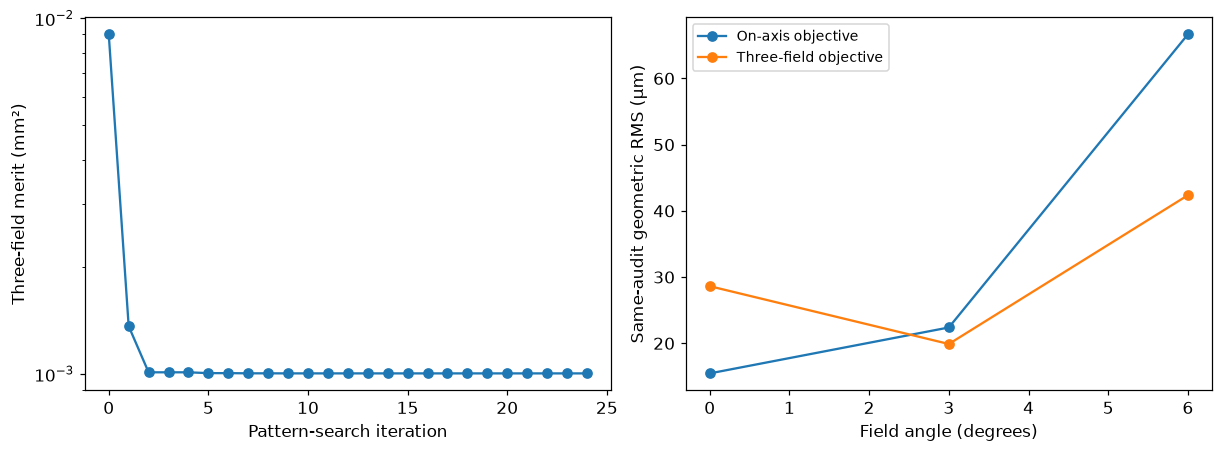

In [5]:
designs={"On-axis objective":optimize_design(q0,aperture,[0.],24),
         "Three-field objective":optimize_design(q0,aperture,fields,24)}
selected=designs["Three-field objective"]["best"]
for name,result in designs.items():
    best=result["best"]
    history=np.array([row["value_mm2"] for row in result["history"]])
    assert np.all(np.diff(history)<=1e-13) and best["valid"]
    assert best["value_mm2"]<result["start"]["value_mm2"]
    assert abs(paraxial(best["lens"])["focal"]-50)<1e-11
    assert best["aperture"]==aperture and all(b["image_z"]==best["image_z"] for b in best["bundles"])
    print(name,": q =",best["shape"],", common z =",best["image_z"],", merit =",best["value_mm2"],"mm²")
fig,ax=plt.subplots(1,2,figsize=(11,4))
history=designs["Three-field objective"]["history"]
ax[0].semilogy([h["value_mm2"] for h in history],"o-")
ax[0].set(xlabel="Pattern-search iteration",ylabel="Three-field merit (mm²)")
for name,result in designs.items():
    best=result["best"]
    values=[1000*trace_bundle(best["lens"],aperture,f,best["image_z"])["rms_mm"] for f in fields]
    ax[1].plot(fields,values,"o-",label=name)
ax[1].set(xlabel="Field angle (degrees)",ylabel="Same-audit geometric RMS (μm)");ax[1].legend(fontsize=9)
show(fig,"02-design-and-tradeoff")

## 4 · Audit the result with checks the optimizer did not use

Use more pupil rays, add the withheld fields 1.5° and 4.5°, and keep the final
physical detector fixed. Check that the joint-plane derivative vanishes, and
deliberately try an oversized aperture to confirm that clipping is penalized.
Sampling convergence and ray accounting are separate from physical-model accuracy.
**Predict:** does on-axis improvement alone guarantee the best result at every field?

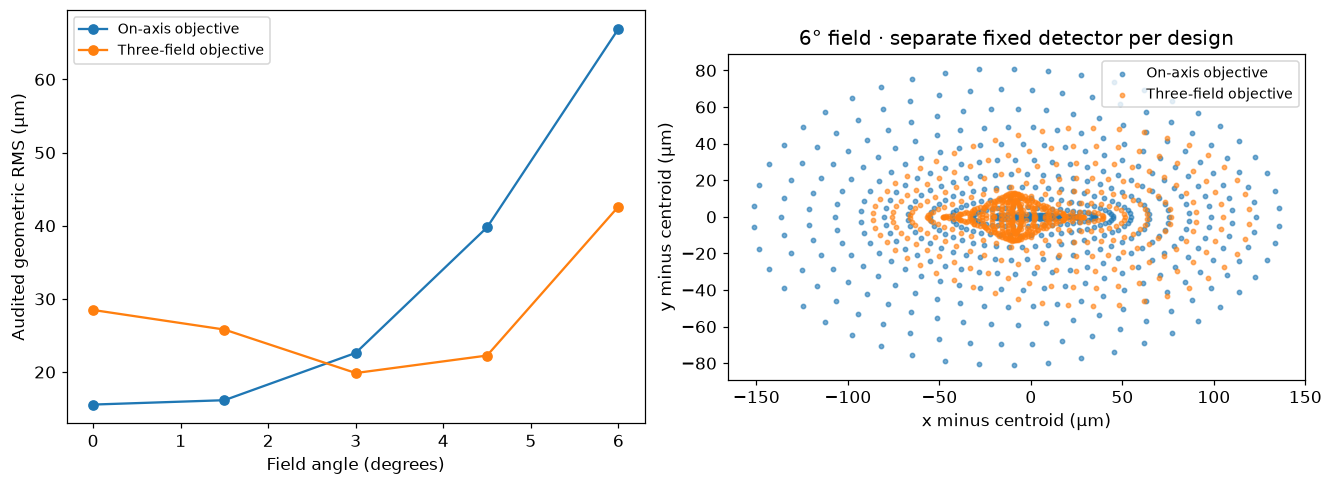

Common-plane derivative: 1.4094628242311558e-15 mm
Pupil-refined merits (same device and plane): [0.0010027688477961614, 0.0010064753122333294, 0.0010074048660047843]
Deliberately oversized stop: lost fraction 0.15624999999999997 penalized merit 1000156.25


In [6]:
q,z=selected["shape"],selected["image_z"]
audit_fields=[0.,1.5,3.,4.5,6.]
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
for name,result in designs.items():
    best=result["best"]
    audit=[trace_bundle(best["lens"],aperture,f,best["image_z"],12,48) for f in audit_fields]
    assert all(b["accepted"]==b["requested"] for b in audit)
    ax[0].plot(audit_fields,[1000*b["rms_mm"] for b in audit],"o-",label=name)
    cloud=np.asarray(audit[-1]["xy"])-audit[-1]["centroid"]
    ax[1].scatter(1000*cloud[:,0],1000*cloud[:,1],s=8,label=name,alpha=.6)
ax[0].set(xlabel="Field angle (degrees)",ylabel="Audited geometric RMS (μm)");ax[0].legend(fontsize=9)
ax[1].set(xlabel="x minus centroid (μm)",ylabel="y minus centroid (μm)",title="6° field · separate fixed detector per design")
ax[1].set_aspect("equal",adjustable="box");ax[1].legend(fontsize=9);show(fig,"03-independent-field-audit")
h=1e-3
derivative=(design_merit(q,z+h,aperture,fields)["value_mm2"]-design_merit(q,z-h,aperture,fields)["value_mm2"])/(2*h)
assert abs(derivative)<1e-9
coarse=design_merit(q,z,aperture,fields,6,16)
fine=design_merit(q,z,aperture,fields,12,48)
finer=design_merit(q,z,aperture,fields,24,96)
assert abs(fine["value_mm2"]/finer["value_mm2"]-1)<.01
clipped=design_merit(q,z,13.,fields)
assert not clipped["valid"] and clipped["loss_fraction"]>0 and clipped["value_mm2"]>=1e6
print("Common-plane derivative:",derivative,"mm")
print("Pupil-refined merits (same device and plane):",[v["value_mm2"] for v in [coarse,fine,finer]])
print("Deliberately oversized stop: lost fraction",clipped["loss_fraction"],"penalized merit",clipped["value_mm2"])

## Optional extension · Perturb the manufactured prescription

The design is a nominal geometric model. Small radius, thickness, and index changes
need not preserve its focal power. Draw seeded perturbations and evaluate them at
the **unchanged** nominal detector with the same aperture and fields. This is a
sensitivity illustration, not a manufacturing-yield prediction: the distributions
are chosen here, and diffraction, real glass dispersion, tilt and decentre are absent.

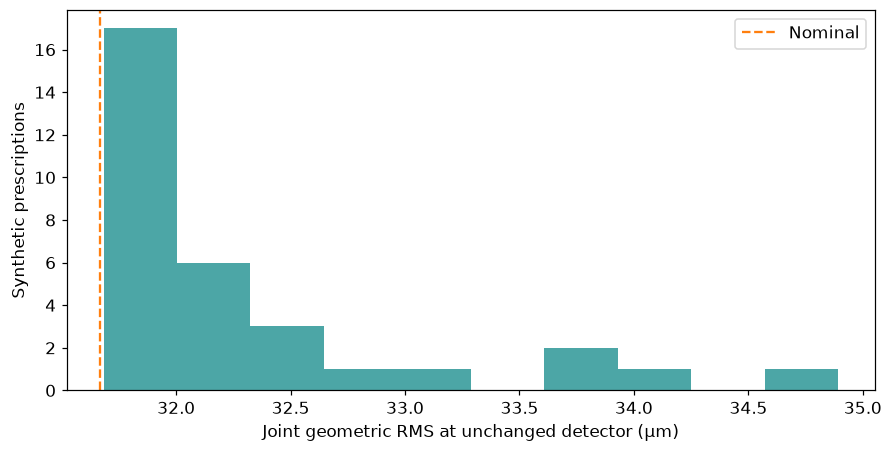

In [7]:
rng=np.random.default_rng(41);nominal=selected["lens"];perturbed=[]
for _ in range(32):
    lens=make_lens(nominal["r1"]+rng.normal(0,.05),nominal["r2"]+rng.normal(0,.05),
                   nominal["thickness"]+rng.normal(0,.02),nominal["index"]+rng.normal(0,.0005),12.)
    audit=[trace_bundle(lens,aperture,f,z) for f in fields]
    assert lens["edge_thickness"]>.5 and all(b["throughput"]==1 for b in audit)
    perturbed.append(1000*np.sqrt(np.mean([b["rms_mm"]**2 for b in audit])))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(perturbed,bins=10,color="teal",alpha=.7)
ax.axvline(1000*selected["rms_mm"],color="tab:orange",ls="--",label="Nominal")
ax.set(xlabel="Joint geometric RMS at unchanged detector (μm)",ylabel="Synthetic prescriptions");ax.legend()
show(fig,"04-prescription-sensitivity")

## A short lab report

**1. State the design contract.** List the variables, fixed focal power, entrance aperture, field weights, common image plane and failure penalties.

**2. Compare two objectives.** Optimize the on-axis and multi-field objectives from the same start. Report all field RMS values and the common image location for each result.

**3. Validate the final prescription.** Re-trace the chosen lens with denser pupil sampling and an intermediate field. Report any change in the ranking and the transmitted-ray fraction.

### Worked reasoning

**State the design contract.** A reproducible design includes both the prescription and the evaluation conditions. Fixed aperture and ray-failure checks prevent a misleading improvement.

**Compare two objectives.** Changing field weights changes the design problem. Judge each result against the same full field table rather than comparing two unlike scalar losses.

**Validate the final prescription.** Independent sampling checks whether the selected solution exploits the evaluation grid. It complements, rather than replaces, a more complete wave and tolerance model.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OCW · Aberrations and optical design (lectures 8–9)](https://ocw.mit.edu/courses/2-71-optics-spring-2009/pages/lecture-slides/)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [8]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e12_figures.zip


/tmp/optics-notebooks-w00ghsb7/E12/e12_figures.zip